# ПР5. Классификация потенциально опасных астероидов

**Задача:** предсказать `pha` (Y/N) по физическим и орбитальным признакам.

**Ключевая особенность (ПР-2):** дисбаланс классов — всего 0.22% объектов Y.
Классификатор «всегда N» даст accuracy 99.78%, не обнаружив ни одного
опасного астероида. Поэтому accuracy не используется как целевая метрика;
основные метрики — precision, recall, F1, PR-AUC.

**Цена ошибки:** ложноотрицательный результат (FN — пропустили опасный
астероид) критичнее ложноположительного (FP — лишнее наблюдение).
Это учтём при подборе порога.

**Схема сравнения:** все методы оцениваются на одном и том же test-наборе
(требование корректности сравнения).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

df = pd.read_csv("../data/raw/dataset.csv", low_memory=False)

# Тот же отбор признаков, что и в ПР-3/ПР-4
drop_cols = [
    "id", "spkid", "full_name", "pdes", "name", "prefix",
    "orbit_id", "equinox",
    "moid_ld", "epoch_mjd", "epoch_cal", "per_y", "tp_cal",
    "diameter_sigma",
    "diameter",  # для классификации не используем (86% пропусков, ПР-2)
]
df_model = df.drop(columns=drop_cols)

clf_data = df_model.dropna(subset=["pha"]).copy()
X = clf_data.drop(columns=["pha"])
y = clf_data["pha"]

# stratify обязателен: иначе Y может не попасть в test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_cols = X_train.select_dtypes(include=["float64", "int64"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["str", "object"]).columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
])

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print("Train:", X_train_prep.shape, "| Test:", X_test_prep.shape)
print("Y в train:", (y_train == "Y").sum(), "| Y в test:", (y_test == "Y").sum())

Train: (750882, 43) | Test: (187721, 43)
Y в train: 1653 | Y в test: 413


## Подготовка обучающей выборки

SMOTE на полном train (750k строк) неприменим из-за объёма памяти.
Обучающая выборка: все объекты Y (1653) + случайные 50 000 объектов N —
дисбаланс сохраняется (~3.2%), размер позволяет сравнить методы быстро.
Test-набор остаётся полным и неизменным для всех методов —
это обеспечивает корректное сравнение.

Учебная выборка: (51653, 43) | Y: 1653

=== Базовая модель (без коррекции) ===
Accuracy:  0.9954
Precision: 0.3175
Recall:    0.9564
F1:        0.4768


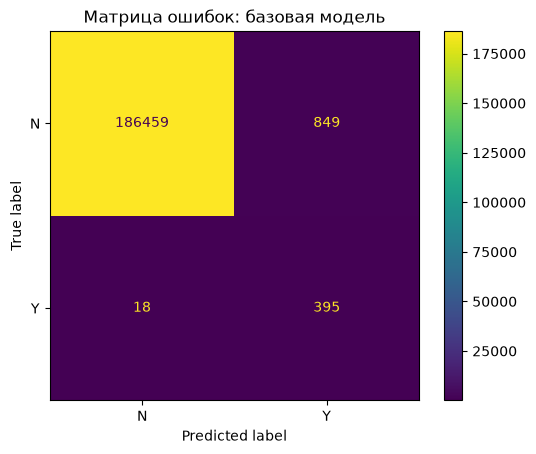

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

# --- Учебная train-выборка: все Y + 50k случайных N (позиции строк!) ---
y_train_arr = (y_train == "Y").values  # True/False в виде массива

idx_Y = np.where(y_train_arr)[0]                       # позиции всех Y
idx_N_all = np.where(~y_train_arr)[0]                  # позиции всех N
rng = np.random.RandomState(42)
idx_N = rng.choice(idx_N_all, size=50_000, replace=False)  # случайные 50k N

idx_pos = np.concatenate([idx_Y, idx_N])               # объединяем позиции

X_sub = X_train_prep[idx_pos]
y_sub = y_train_arr[idx_pos].astype(int)               # Y=1, N=0

# Test-цель тоже в 0/1
y_test_bin = (y_test == "Y").astype(int)

print("Учебная выборка:", X_sub.shape, "| Y:", y_sub.sum())

# --- Базовая модель БЕЗ коррекции дисбаланса ---
baseline = LogisticRegression(max_iter=1000, random_state=42)
baseline.fit(X_sub, y_sub)

y_pred_base = baseline.predict(X_test_prep)

print("\n=== Базовая модель (без коррекции) ===")
print(f"Accuracy:  {accuracy_score(y_test_bin, y_pred_base):.4f}")
print(f"Precision: {precision_score(y_test_bin, y_pred_base, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test_bin, y_pred_base, zero_division=0):.4f}")
print(f"F1:        {f1_score(y_test_bin, y_pred_base, zero_division=0):.4f}")

ConfusionMatrixDisplay.from_predictions(y_test_bin, y_pred_base,
                                        display_labels=["N", "Y"])
plt.title("Матрица ошибок: базовая модель")
plt.show()

### Базовая модель (без коррекции дисбаланса)

| Метрика | Значение |
|---|---|
| Accuracy | 0.9954 |
| Precision | 0.3175 |
| Recall | 0.9564 |
| F1 | 0.4768 |

**Интерпретация:** accuracy высокая, но при дисбалансе 0.22% это не
показатель качества. Recall = 0.96: модель обнаруживает почти все
опасные астероиды (18 FN из 413) — благодаря признаку MOID, который,
как выяснено в ПР-2, почти однозначно определяет класс.

Проблема — precision = 0.32: 849 из 1244 тревог ложные. В терминах
задачи: на каждые 3 объекта, отправленные на дополнительное наблюдение,
2 оказываются обычными астероидами — растрата ресурсов телескопов.

**Цель дальнейшей работы:** повысить precision и F1 без существенной
потери recall (цена FN всё ещё выше цены FP).

In [3]:
from imblearn.over_sampling import SMOTE

# --- Метод 1: class_weight='balanced' ---
model_cw = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
model_cw.fit(X_sub, y_sub)
y_pred_cw = model_cw.predict(X_test_prep)

# --- Метод 2: SMOTE (только на обучающей выборке!) ---
smote = SMOTE(random_state=42)
X_sm, y_sm = smote.fit_resample(X_sub, y_sub)
print("После SMOTE:", X_sm.shape, "| Y:", y_sm.sum())

model_sm = LogisticRegression(max_iter=1000, random_state=42)
model_sm.fit(X_sm, y_sm)
y_pred_sm = model_sm.predict(X_test_prep)

# --- Сводная таблица ---
def metrics(name, y_true, y_pred):
    return {
        "model": name,
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "precision": round(precision_score(y_true, y_pred, zero_division=0), 4),
        "recall": round(recall_score(y_true, y_pred, zero_division=0), 4),
        "F1": round(f1_score(y_true, y_pred, zero_division=0), 4),
    }

results = pd.DataFrame([
    metrics("baseline (no correction)", y_test_bin, y_pred_base),
    metrics("class_weight=balanced", y_test_bin, y_pred_cw),
    metrics("SMOTE", y_test_bin, y_pred_sm),
])
results

После SMOTE: (100000, 43) | Y: 50000


,model,accuracy,precision,recall,F1
0,baseline (no correction),0.9954,0.3175,0.9564,0.4768
1,class_weight=balanced,0.9887,0.1632,1.0000,0.2807
2,SMOTE,0.9903,0.1844,1.0000,0.3113


### Сравнение методов борьбы с дисбалансом

| Метод | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| baseline (без коррекции) | 0.9954 | **0.3175** | 0.9564 | **0.4768** |
| class_weight='balanced' | 0.9887 | 0.1632 | 1.0000 | 0.2807 |
| SMOTE | 0.9903 | 0.1844 | 1.0000 | 0.3113 |

Методы коррекции дисбаланса (class_weight, SMOTE) доводят recall до 1.0,
но сильно снижают precision: модель начинает относить к классу Y слишком
много обычных астероидов (рост FP с 849 до ~2000). F1 ухудшается.

**Причина:** сигнал MOID (ПР-2) и без коррекции почти идеально разделяет
классы; дополнительное «давление» в сторону миноритарного класса лишь
размывает границу решения.

**Вывод:** ресэмплинг для данного датасета контрпродуктивен. Оптимальный
инструмент — подбор порога классификации: сдвиг границы решения позволяет
настроить баланс precision/recall под цену ошибки без переобучения.

Оптимальный порог по F1: 0.7179
При пороге 0.7179: precision=0.4282, recall=0.8523, F1=0.5700


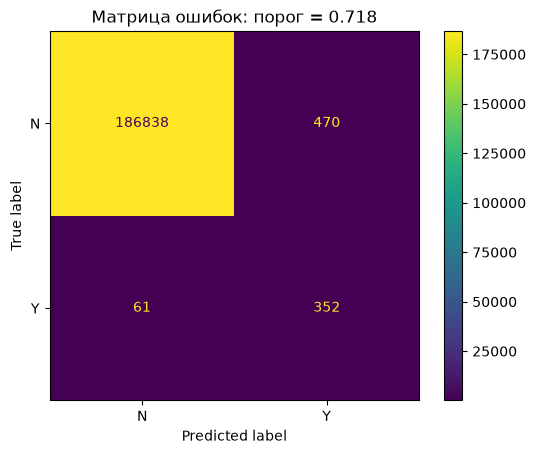

In [4]:
from sklearn.metrics import precision_recall_curve

# Вероятности класса Y у baseline-модели
y_proba_base = baseline.predict_proba(X_test_prep)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_test_bin, y_proba_base)

# F1 для каждого порога
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print(f"Оптимальный порог по F1: {best_threshold:.4f}")
print(f"При пороге {best_threshold:.4f}: precision={precisions[best_idx]:.4f}, "
      f"recall={recalls[best_idx]:.4f}, F1={f1_scores[best_idx]:.4f}")

# Применяем новый порог
y_pred_thr = (y_proba_base >= best_threshold).astype(int)

ConfusionMatrixDisplay.from_predictions(y_test_bin, y_pred_thr,
                                        display_labels=["N", "Y"])
plt.title(f"Матрица ошибок: порог = {best_threshold:.3f}")
plt.show()

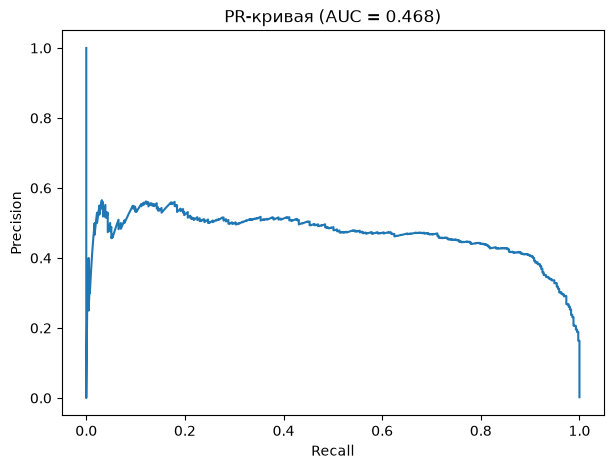

In [5]:
from sklearn.metrics import auc

pr_auc = auc(recalls, precisions)

plt.figure(figsize=(7, 5))
plt.plot(recalls, precisions)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"PR-кривая (AUC = {pr_auc:.3f})")
plt.show()

### Подбор порога классификации

| Порог | FP | FN | Precision | Recall | F1 |
|---|---|---|---|---|---|
| 0.5 (default) | 849 | 18 | 0.317 | 0.956 | 0.477 |
| 0.718 (max F1) | 470 | 61 | 0.428 | 0.852 | **0.570** |

Порог 0.718 увеличил F1 на 19% и сократил ложные тревоги почти вдвое,
незначительно снизив recall (с 0.956 до 0.852). PR-AUC = 0.468.

**Цена ошибки:** FN (пропущенный PHA) критичнее FP (лишнее наблюдение).
Если отношение цен, например, 5:1, оправдан более низкий порог с выше
recall. Порог — инженерно-бизнес решение, а не константа 0.5.

### Итог ПР-5

1. Дисбаланс 0.22% делает accuracy бесполезной метрикой — использованы
   precision, recall, F1, confusion matrix, PR-кривая.
2. Ресэмплинг (class_weight, SMOTE) ухудшил F1 — сигнал MOID и без
   коррекции разделяет классы; доказано сравнением на едином test.
3. Подбор порога — рабочий инструмент: F1 0.477 → 0.570.
4. Модель пригодна для демо-инструмента оценки опасности (итоговый проект).